<a href="https://colab.research.google.com/github/Nasim-Amani/tag-recommender-agent-learning/blob/main/Phase1_NLP_Foundations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 1 — NLP Foundations for Product Tagging
**Tag Recommender Agent roadmap**

In this notebook you will:
1. **Load** real Amazon product metadata (All_Beauty, Amazon Reviews 2023)
2. **Explore** the data and **build tags** from the `details` attributes
3. Learn **text basics**: cleaning, tokenization, **TF-IDF**
4. Learn **embeddings** (sentence-transformers) and semantic search
5. Learn **spaCy** POS tagging + dependency parsing and extract **syntactic patterns** → the core of your proposal
6. **Save** everything for Phase 2 (baselines)

### Your time-series intuition → NLP
| Time series | Text |
|---|---|
| raw signal, resampling, cleaning | raw text, normalization, cleaning |
| windowing / lag features | tokenization, n-grams |
| hand-crafted features (FFT, stats) | TF-IDF |
| learned representation (LSTM hidden state) | embeddings (BERT / sentence-transformers) |
| domain rules (e.g., physical limits) | syntactic patterns (spaCy) |

> **Runtime:** `Runtime → Change runtime type → T4 GPU` (only needed for the embeddings section, everything else runs on CPU).

## 0 · Setup

In [11]:
!pip -q install -U spacy sentence-transformers huggingface_hub
!python -m spacy download en_core_web_sm -q

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [12]:
import json, re, gzip, itertools, random, urllib.request
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 120)
random.seed(42); np.random.seed(42)

## 1 · Load the data
We read the **item metadata** of the *All_Beauty* category (~113k products, 213 MB).
To keep things fast we take the first `N_PRODUCTS` products — increase it later.

Each product looks like this (abridged):
```json
{"title": "Lurrose 100Pcs Full Cover Fake Toenails ...",
 "features": ["The false toenails are durable ..."],
 "description": ["Description", "...", "Feature", "- Color: As Shown.- Material: ABS. ..."],
 "store": "Lurrose", "categories": [],
 "details": {"Color": "As Shown", "Brand": "Lurrose", "Material": "Acrylonitrile Butadiene Styrene (ABS)", "UPC": "...", "Manufacturer": "Lurrose"},
 "parent_asin": "B07G9GWFSM"}
```
👉 `title + features + description` = **vendor text** (input) · `details` = **attribute–value pairs** (our tags / labels).

In [13]:
CATEGORY    = "All_Beauty"
N_PRODUCTS  = 30_000      # start small; the full file has ~113k products
DATA_PATH   = None        # set to a local .jsonl / .jsonl.gz path to skip downloading

def download_meta(category):
    # Option A: Hugging Face Hub (fast in Colab)
    try:
        from huggingface_hub import hf_hub_download
        return hf_hub_download("McAuley-Lab/Amazon-Reviews-2023",
                               f"raw/meta_categories/meta_{category}.jsonl",
                               repo_type="dataset")
    except Exception as e:
        print("HF download failed, trying UCSD mirror:", e)
    # Option B: UCSD mirror
    url  = f"https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/meta_categories/meta_{category}.jsonl.gz"
    path = f"meta_{category}.jsonl.gz"
    urllib.request.urlretrieve(url, path)
    return path

path   = DATA_PATH or download_meta(CATEGORY)
opener = gzip.open if str(path).endswith(".gz") else open
with opener(path, "rt", encoding="utf-8") as f:
    rows = [json.loads(line) for line in itertools.islice(f, N_PRODUCTS)]

df = pd.DataFrame(rows)
print(df.shape)
df.head(3)

(30000, 14)


,main_category,title,average_rating,rating_number,features,description,price,images,videos,store,categories,details,parent_asin,bought_together
0,All Beauty,"Howard LC0008 Leather Conditioner, 8-Ounce (4-Pack)",4.8,10,[],[],NaN,"[{'thumb': 'https://m.media-amazon.com/images/I/41qfjSfqNyL._SS40_.jpg', 'large': 'https://m.media-amazon.com/images...",[],Howard Products,[],"{'Package Dimensions': '7.1 x 5.5 x 3 inches; 2.38 Pounds', 'UPC': '617390882781'}",B01CUPMQZE,None
1,All Beauty,"Yes to Tomatoes Detoxifying Charcoal Cleanser (Pack of 2) with Charcoal Powder, Tomato Fruit Extract, and Gingko Bil...",4.5,3,[],[],NaN,"[{'thumb': 'https://m.media-amazon.com/images/I/41b+11d5igL._SS40_.jpg', 'large': 'https://m.media-amazon.com/images...",[],Yes To,[],"{'Item Form': 'Powder', 'Skin Type': 'Acne Prone', 'Brand': 'Yes To', 'Age Range (Description)': 'Adult', 'Unit Coun...",B076WQZGPM,None
2,All Beauty,Eye Patch Black Adult with Tie Band (6 Per Pack),4.4,26,[],[],NaN,"[{'thumb': 'https://m.media-amazon.com/images/I/31bz+uqzWCL._SS40_.jpg', 'large': 'https://m.media-amazon.com/images...",[],Levine Health Products,[],{'Manufacturer': 'Levine Health Products'},B000B658RI,None


## 2 · Exploratory data analysis
Same mindset as checking a sensor series for gaps and outliers: **what is missing, how long are the texts, which attributes exist?**

In [14]:
def as_text(x):
    # features/description are lists of strings; title is a string
    if isinstance(x, list):
        return " ".join(str(s) for s in x if s)
    return "" if x is None or (isinstance(x, float) and np.isnan(x)) else str(x)

df["title_txt"]    = df["title"].apply(as_text)
df["features_txt"] = df["features"].apply(as_text)
df["desc_txt"]     = df["description"].apply(as_text)
df["text"] = (df["title_txt"] + ". " + df["features_txt"] + " " + df["desc_txt"]).str.strip()

is_empty = lambda s: s.str.strip().eq("")
summary = pd.Series({
    "products":                 len(df),
    "empty title (%)":          100 * is_empty(df["title_txt"]).mean(),
    "empty features (%)":       100 * is_empty(df["features_txt"]).mean(),
    "empty description (%)":    100 * is_empty(df["desc_txt"]).mean(),
    "empty categories (%)":     100 * df["categories"].apply(lambda c: not c).mean(),
    "has details dict (%)":     100 * df["details"].apply(lambda d: isinstance(d, dict) and len(d) > 0).mean(),
}).round(1)
summary

,0
products,30000.0
empty title (%),0.0
empty features (%),83.3
empty description (%),81.8
empty categories (%),100.0
has details dict (%),97.3


details is a small dictionary of attribute–value pairs that each product carries, for example:

{"Brand": "Lurrose", "Color": "As Shown", "Material": "ABS", "UPC": "7997...", "Manufacturer": "Lurrose"}

So 97.3% means that 97.3% of products have at least one attribute in this dictionary, and only 2.7% have none. This is good news: details is where your tags (labels) come from, so nearly every product has labels.

In [15]:
df["details"].head(5).tolist()

[{'Package Dimensions': '7.1 x 5.5 x 3 inches; 2.38 Pounds',
  'UPC': '617390882781'},
 {'Item Form': 'Powder',
  'Skin Type': 'Acne Prone',
  'Brand': 'Yes To',
  'Age Range (Description)': 'Adult',
  'Unit Count': '10 Fl Oz',
  'Is Discontinued By Manufacturer': 'No',
  'Item model number': 'SG_B076WQZGPM_US',
  'UPC': '653801351125',
  'Manufacturer': 'Yes to Tomatoes'},
 {'Manufacturer': 'Levine Health Products'},
 {'Brand': 'Cherioll',
  'Item Form': 'Powder',
  'Finish Type': 'Natural',
  'Product Benefits': 'Long Lasting',
  'Skin Type': 'All',
  'Package Dimensions': '8.43 x 5.91 x 0.87 inches; 8.78 Ounces',
  'Item model number': 'eyebrow sticker001'},
 {'UPC': '644287689178'}]

One rule to keep in mind: never put details into the input text. It is your answer key. Using it as input would be like feeding a forecasting model the future values it’s supposed to predict (data leakage).

The following cell counts the words in each product’s text, draws a histogram of those counts, and prints summary statistics. It answers the question “how long are the product texts?

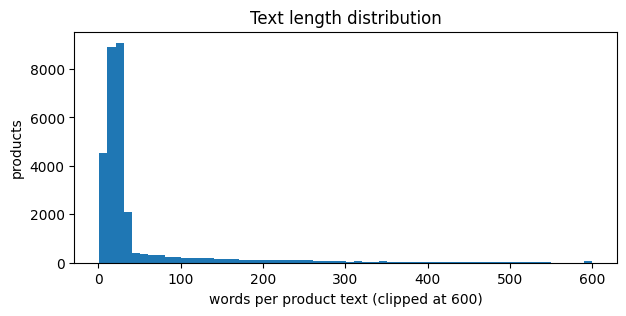

,n_words
count,30000.0
mean,48.0
std,84.0
min,1.0
25%,14.0
50%,22.0
75%,30.0
max,893.0


In [16]:
df["n_words"] = df["text"].str.split().str.len()
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(df["n_words"].clip(upper=600), bins=60)
ax.set_xlabel("words per product text (clipped at 600)"); ax.set_ylabel("products")
ax.set_title("Text length distribution")
plt.show()
df["n_words"].describe().round(0)

The following cell puts every product into one of two groups by text length, then shows what share of products falls in each group.

In [17]:
data_len_group = np.where(df["n_words"] <= 40, "short (title-only)", "long (rich text)")
df["len_group"] = data_len_group
df["len_group"].value_counts(normalize=True).round(3)

,proportion
len_group,
short (title-only),0.821
long (rich text),0.179


### Which attributes live in `details`?
Some keys are real product attributes (Color, Material, Skin Type…), others are IDs or logistics (UPC, Dimensions…). We keep only the real attributes.

In [18]:
key_counts = Counter(k for d in df["details"] if isinstance(d, dict) for k in d)
pd.DataFrame(key_counts.most_common(40), columns=["attribute", "products"]).assign(
    pct=lambda t: (100 * t["products"] / len(df)).round(1))

,attribute,products,pct
0,Brand,20743,69.1
1,Package Dimensions,18540,61.8
2,UPC,16944,56.5
3,Is Discontinued By Manufacturer,11184,37.3
4,Item Form,9509,31.7
5,Material,8629,28.8
6,Unit Count,7531,25.1
7,Hair Type,7393,24.6
8,Age Range (Description),6710,22.4
9,Product Dimensions,6444,21.5


Look inside every product’s details dictionary, count how many products have each attribute name, then show the 40 most common ones with their count and percentage.

## 3 · Build tags from `details`
A **tag** = `Attribute=value`, e.g. `Material=aloe vera`, `Skin Type=dry`.
Steps:
1. drop ID / logistics attributes
2. keep attributes present in ≥ `MIN_ATTR_PCT` % of products
3. normalize values (lower-case, trim) and split multi-values (`"Dry, Oily"` → 2 tags)
4. keep tags that occur ≥ `MIN_TAG_FREQ` times (rare tags are noise for now — the long tail is a research topic for later)

This makes the task **multi-label classification**: each product → a *set* of tags (like multi-output forecasting).

In [19]:
EXCLUDE = {
    "UPC", "Manufacturer", "Date First Available", "Item model number", "ASIN",
    "Package Dimensions", "Product Dimensions", "Item Weight", "Item Package Dimensions L x W x H",
    "Is Discontinued By Manufacturer", "Best Sellers Rank", "Customer Reviews",
    "Global Trade Identification Number", "Batteries", "Batteries Required",
    "Number of Items", "Unit Count", "Item Package Quantity", "Package Weight",
    "Manufacturer Part Number", "Department", "Language",
}
MIN_ATTR_PCT = 2.0     # attribute must appear in at least 2% of products
MIN_TAG_FREQ = 30      # tag must appear at least 30 times
MAX_VALUE_LEN = 40     # very long values are usually free text, not tags

TAG_ATTRS = [k for k, c in key_counts.most_common()
             if k not in EXCLUDE and 100 * c / len(df) >= MIN_ATTR_PCT]
print("Attributes used as tags:", TAG_ATTRS)

def norm_value(v):
    v = str(v).lower().strip()
    v = re.sub(r"\s+", " ", v)
    return v.strip(" .;:-")

def details_to_tags(d):
    if not isinstance(d, dict):
        return []
    tags = set()
    for attr in TAG_ATTRS:
        if d.get(attr):
            for v in re.split(r"[,;]", str(d[attr])):
                v = norm_value(v)
                if v and len(v) <= MAX_VALUE_LEN:
                    tags.add(f"{attr}={v}")
    return sorted(tags)

df["raw_tags"] = df["details"].apply(details_to_tags)
tag_freq = Counter(t for ts in df["raw_tags"] for t in ts)
KEEP = {t for t, c in tag_freq.items() if c >= MIN_TAG_FREQ}
df["tags"] = df["raw_tags"].apply(lambda ts: [t for t in ts if t in KEEP])

data = df[df["tags"].str.len() > 0].reset_index(drop=True)
print(f"unique raw tags: {len(tag_freq):,} -> kept tags: {len(KEEP):,}")
print(f"products with >=1 kept tag: {len(data):,} / {len(df):,}")
data[["title_txt", "tags"]].head(8)

Attributes used as tags: ['Brand', 'Item Form', 'Material', 'Hair Type', 'Age Range (Description)', 'Skin Type', 'Material Feature', 'Color', 'Style', 'Scent', 'Finish Type', 'Extension Length', 'Special Feature', 'Product Benefits', 'Number of Pieces', 'Item Dimensions LxWxH', 'Item Volume', 'Installation Type', 'Liquid Volume', 'Size', 'Package Information', 'Coverage', 'Recommended Uses For Product']
unique raw tags: 15,063 -> kept tags: 298
products with >=1 kept tag: 21,173 / 30,000


,title_txt,tags
0,"Yes to Tomatoes Detoxifying Charcoal Cleanser (Pack of 2) with Charcoal Powder, Tomato Fruit Extract, and Gingko Bil...","[Age Range (Description)=adult, Item Form=powder, Skin Type=acne prone]"
1,"Tattoo Eyebrow Stickers, Waterproof Eyebrow, 4D Imitation Eyebrow Tattoos, 4D Hair-like Authentic Eyebrows Waterproo...","[Finish Type=natural, Item Form=powder, Product Benefits=long lasting, Skin Type=all]"
2,Lurrose 100Pcs Full Cover Fake Toenails Artificial Transparent Nail Tips Nail Art for DIY,"[Material=acrylonitrile butadiene styrene (abs), Size=large, Style=french]"
3,Stain Bonnet For Baby Bonnet Silk Sleep Cap For Toddler Child Shower Cap Teens Kids,"[Material=silk, Size=1 count (pack of 1)]"
4,Gold extatic Musk EDT 90ml,"[Age Range (Description)=adult, Item Form=spray, Style=modern]"
5,Avon Big & False Lash Mascara - Brown/Black by Big & False Lash,"[Brand=avon, Color=black, Item Volume=10 milliliters, Package Information=tube]"
6,"Stainless Steel Beard Comb, Portable Fashionable Engraving Design Mustache Hair Comb for Beard Trimming Styling and ...","[Hair Type=all, Material=metal]"
7,Nomade By Chloe,"[Age Range (Description)=adult, Item Volume=100 milliliters, Style=modern]"


### 🏷️ Building tags from `details`

**In plain words:** this cell turns every product's `details` dictionary into a clean list of tags like `Skin Type=dry`, and throws away the useless and rare ones.

**Block by block:**
- **`EXCLUDE = {...}`**: the attributes we never use as tags, because they don't describe *what the product is*:
  - **IDs** (UPC, ASIN, model number) are unique per product, so there's nothing to learn.
  - **Measurements** (volume, size, weight, dimensions) are numbers written in endless formats ("100 ml", "3.4 fl oz"). They should be *extracted* with number + unit patterns, not predicted as tags.
  - **Logistics** fields (discontinued, unit count, package dimensions) matter to a warehouse, not to a customer.
  - **Brand** is also left out (in the improved version). It has thousands of values, it's usually already in the title, and it would inflate the scores.
  - ✅ What's left (Skin Type, Item Form, Material, Scent…) has a few repeating values that customers filter by, and those make good tags.
- **The three settings**: an attribute must appear in ≥ 2% of products, a tag must appear in ≥ 30 products, and a value longer than 40 characters is ignored (it's a sentence, not a tag).
- **`TAG_ATTRS = [...]`**: keeps the attributes that are *not excluded* and *common enough*. This is the final list of attributes turned into tags.
- **`norm_value(v)`**: cleans one value, so `"  Dry Skin. "` becomes `"dry skin"`.
- **`details_to_tags(d)`**: for one product, takes each chosen attribute, splits values at commas (`"Dry, Oily"` → 2 values), cleans them, and builds tags like `Skin Type=dry`.
- **Last block**: applies this to all products, counts each tag, keeps only tags with ≥ 30 products, and keeps only products that still have ≥ 1 tag.

**Result:** 30,000 products → 15,063 raw tags → **298 common tags** → **21,173 products with tags**.

* details → raw_tags: applies the rules to each product’s details: skip excluded or uncommon attributes, clean the values, split them at commas, and drop values that are too long.
* raw_tags → tags: removes rare tags (those in fewer than 30 products). So tags is a filtered version of raw_tags, not something new built from details.
* tags → data: keeps only the products whose tags isn’t empty.

### 🔁 What this cell produces: `details` → `raw_tags` → `tags` → `data`

1. **`details` → `raw_tags`**: apply the rules to each product's `details`: skip excluded or uncommon attributes, clean the values, split them at commas, and drop values that are too long.
2. **`raw_tags` → `tags`**: remove rare tags (fewer than 30 products). `tags` is a *filtered* version of `raw_tags`.
3. **`tags` → `data`**: keep only the products whose `tags` list isn't empty.

**Important:** the rules remove **tags**, not rows. A product keeps its good tags and loses only the bad ones (UPC, rare values…). A row is dropped **only if no tags are left at all**, e.g. a product whose `details` had only UPC and Package Dimensions.

**Result:**
- `df` → all **30,000** products (with the new `raw_tags` and `tags` columns)
- `data` → **21,173** products with at least 1 tag, **all columns kept**, rows renumbered 0, 1, 2…
- From here on, the notebook works with **`data`**.



In [20]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21173 entries, 0 to 21172
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   main_category    21173 non-null  object 
 1   title            21173 non-null  object 
 2   average_rating   21173 non-null  float64
 3   rating_number    21173 non-null  int64  
 4   features         21173 non-null  object 
 5   description      21173 non-null  object 
 6   price            4240 non-null   float64
 7   images           21173 non-null  object 
 8   videos           21173 non-null  object 
 9   store            20113 non-null  object 
 10  categories       21173 non-null  object 
 11  details          21173 non-null  object 
 12  parent_asin      21173 non-null  object 
 13  bought_together  0 non-null      object 
 14  title_txt        21173 non-null  object 
 15  features_txt     21173 non-null  object 
 16  desc_txt         21173 non-null  object 
 17  text        

In [21]:
for attr in ["UPC", "Item Volume", "Size", "Brand", "Skin Type", "Item Form", "Scent"]:
    vals = [d[attr] for d in df["details"] if isinstance(d, dict) and attr in d]
    print(f"{attr:12s} products={len(vals):6d}  unique values={len(set(vals)):6d}")

UPC          products= 16944  unique values= 16856
Item Volume  products=  1242  unique values=   181
Size         products=  1051  unique values=   284
Brand        products= 20743  unique values= 10244
Skin Type    products=  3442  unique values=   114
Item Form    products=  9509  unique values=   380
Scent        products=  2471  unique values=   779


In plain words: for 7 attributes, this cell counts how many products have the attribute and how many different values it takes. It shows which attributes behave like categories (few values that repeat) and which behave like IDs (almost every value different).

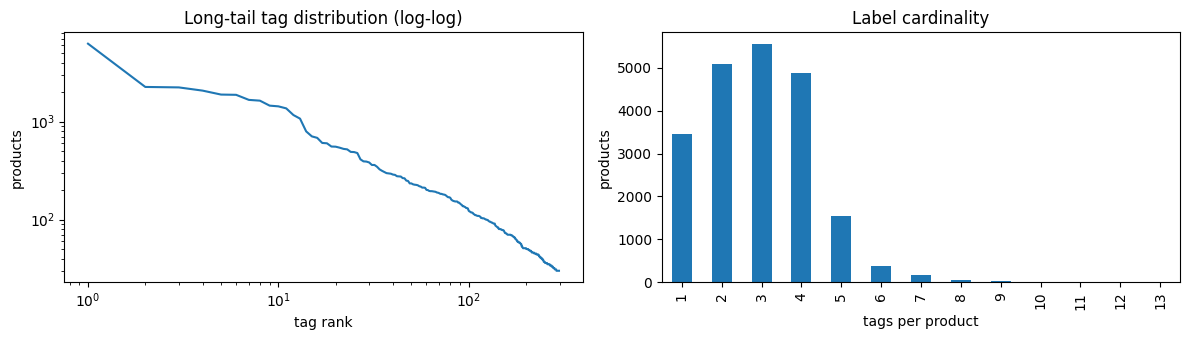

,0
Age Range (Description)=adult,6253
Material=human hair,2261
Material Feature=natural,2237
Hair Type=straight,2074
Skin Type=all,1890
Hair Type=curly,1879
Hair Type=wavy,1668
Style=modern,1638
Hair Type=all,1457
Material=synthetic,1433


In [22]:
kept_freq = pd.Series({t: tag_freq[t] for t in KEEP}).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(np.arange(1, len(kept_freq) + 1), kept_freq.values)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("tag rank"); axes[0].set_ylabel("products"); axes[0].set_title("Long-tail tag distribution (log-log)")
data["tags"].str.len().value_counts().sort_index().plot.bar(ax=axes[1])
axes[1].set_xlabel("tags per product"); axes[1].set_ylabel("products"); axes[1].set_title("Label cardinality")
plt.tight_layout(); plt.show()

kept_freq.head(25)

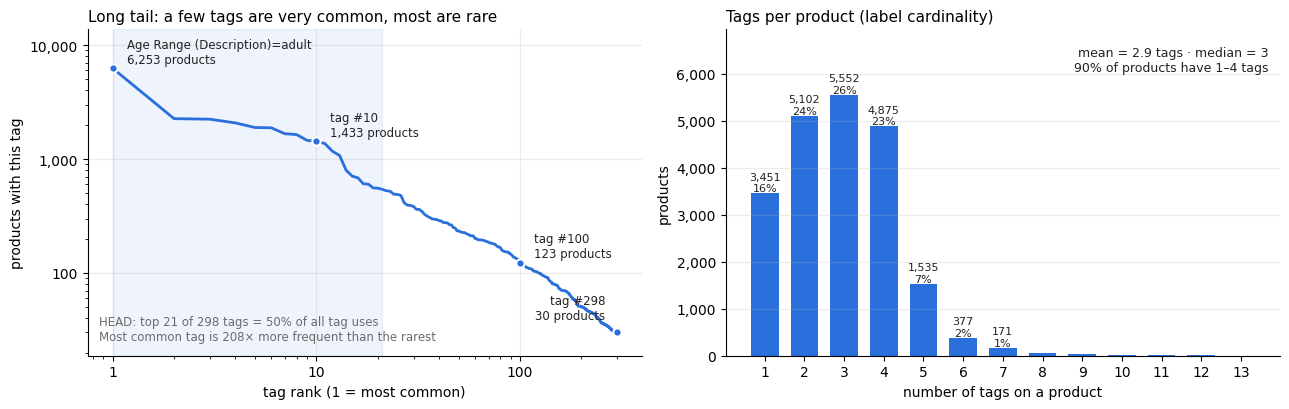

Tags kept: 298 | products: 21,173
Head: top 21 tags cover 50% of all tag uses
Most common: Age Range (Description)=adult (6,253) | rarest kept: 30 products
Tags per product: mean 2.92, median 3, 1–4 tags = 89.6%


,0
Age Range (Description)=adult,6253
Material=human hair,2261
Material Feature=natural,2237
Hair Type=straight,2074
Skin Type=all,1890
Hair Type=curly,1879
Hair Type=wavy,1668
Style=modern,1638
Hair Type=all,1457
Material=synthetic,1433


In [23]:
from matplotlib.ticker import FuncFormatter

kept_freq = pd.Series({t: tag_freq[t] for t in KEEP}).sort_values(ascending=False)
ranks = np.arange(1, len(kept_freq) + 1)
n_tags = data["tags"].str.len()
INK, MUTED, BLUE = "#222222", "#6b6b6b", "#2a6fdb"
plain = FuncFormatter(lambda v, _: f"{v:,.0f}")

# how many top tags cover half of all tag uses (the "head")
cum_share = kept_freq.cumsum() / kept_freq.sum()
head_n = int((cum_share < 0.5).sum()) + 1

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# ---- Left: long tail, with key points labelled -------------------------------
ax = axes[0]
ax.plot(ranks, kept_freq.values, color=BLUE, lw=2)
ax.axvspan(1, head_n, color=BLUE, alpha=0.08)
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(plain); ax.yaxis.set_major_formatter(plain)
ax.xaxis.set_minor_formatter(FuncFormatter(lambda v, _: "")); ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
ax.set_ylim(kept_freq.min() / 1.6, kept_freq.max() * 2.2)
for r in sorted({1, 10, 100, len(kept_freq)}):
    if r > len(kept_freq): continue
    y = kept_freq.iloc[r - 1]
    ax.plot(r, y, "o", ms=6, color=BLUE, mec="white", mew=1.5)
    name = kept_freq.index[r - 1] if r == 1 else f"tag #{r}"
    ax.annotate(f"{name}\n{y:,} products", (r, y), textcoords="offset points",
                xytext=(10, 4) if r < len(kept_freq) else (-8, 10),
                ha="left" if r < len(kept_freq) else "right", fontsize=8.5, color=INK)
ax.text(0.02, 0.04,
        f"HEAD: top {head_n} of {len(kept_freq)} tags = 50% of all tag uses\n"
        f"Most common tag is {kept_freq.iloc[0] / kept_freq.iloc[-1]:,.0f}× more frequent than the rarest",
        transform=ax.transAxes, fontsize=8.5, color=MUTED, va="bottom")
ax.set_xlabel("tag rank (1 = most common)"); ax.set_ylabel("products with this tag")
ax.set_title("Long tail: a few tags are very common, most are rare", fontsize=11, loc="left")
ax.grid(alpha=0.25, which="major"); ax.spines[["top", "right"]].set_visible(False)

# ---- Right: tags per product, with counts and % on every bar ------------------
ax = axes[1]
vc = n_tags.value_counts().sort_index()
bars = ax.bar(vc.index.astype(str), vc.values, color=BLUE, width=0.7)
for b, v in zip(bars, vc.values):
    pct = 100 * v / len(n_tags)
    if pct >= 0.5:
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n{pct:.0f}%",
                ha="center", va="bottom", fontsize=8, color=INK)
share_1_4 = 100 * (n_tags <= 4).mean()
ax.text(0.98, 0.95,
        f"mean = {n_tags.mean():.1f} tags · median = {n_tags.median():.0f}\n"
        f"{share_1_4:.0f}% of products have 1–4 tags",
        transform=ax.transAxes, ha="right", va="top", fontsize=9, color=INK)
ax.set_ylim(0, vc.max() * 1.25)
ax.yaxis.set_major_formatter(plain)
ax.set_xlabel("number of tags on a product"); ax.set_ylabel("products")
ax.set_title("Tags per product (label cardinality)", fontsize=11, loc="left")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25)

plt.tight_layout(); plt.show()

# ---- Same numbers as text, for your notes ------------------------------------
print(f"Tags kept: {len(kept_freq)} | products: {len(data):,}")
print(f"Head: top {head_n} tags cover 50% of all tag uses")
print(f"Most common: {kept_freq.index[0]} ({kept_freq.iloc[0]:,}) | rarest kept: {kept_freq.iloc[-1]:,} products")
print(f"Tags per product: mean {n_tags.mean():.2f}, median {n_tags.median():.0f}, 1–4 tags = {share_1_4:.1f}%")
kept_freq.head(25)

### 📊 Interpretation: tag distribution (before cleaning)

**Left: long tail**
- The **top 21 of 298 tags** cover **50%** of all tag uses; the other 277 tags share the rest.
- The most common tag (`Age Range=adult`, 6,253 products) is **208× more frequent** than the rarest (30 products).
- Steady drop: rank 10 → 1,433 · rank 100 → 123 · rank 298 → 30.
- **So:** the model will learn common tags well and rare ones poorly → report **macro-F1** (every tag counts equally) as well as micro-F1.

**Right: tags per product**
- **Mean 2.9, median 3**; **90%** of products have 1–4 tags; only ~3% have 6 or more.
- **So:** evaluate with **top-3** (typical product) and **top-5** (covers almost all).

**⚠️ Note:** these numbers use the *old* tag settings. Uninformative tags (`Age Range=adult`, `Skin Type=all`, `Hair Type=all`, `Style=modern`) and a logistics tag (`Package Information=tube`) are still included. After applying `TAG_ATTRS` + `BAD_VALUES`, rerun and compare: expect a smaller head, fewer products, and fewer tags per product.

### Teaser for Phase 4 — which tags appear *together*?
These co-occurrences are the **neighbouring tag attributes** of your proposal (they will become graph edges).

In [24]:
pair_counts = Counter()
for ts in data["tags"]:
    for a, b in itertools.combinations(sorted(ts), 2):
        if a.split("=")[0] != b.split("=")[0]:          # pairs across different attributes
            pair_counts[(a, b)] += 1
pd.DataFrame([(a, b, c) for (a, b), c in pair_counts.most_common(15)],
             columns=["tag A", "tag B", "co-occurrences"])

,tag A,tag B,co-occurrences
0,Age Range (Description)=adult,Style=modern,1085
1,Hair Type=straight,Material=human hair,992
2,Material Feature=natural,Material=human hair,887
3,Hair Type=wavy,Material=human hair,732
4,Hair Type=straight,Material Feature=natural,698
5,Age Range (Description)=adult,Skin Type=all,606
6,Age Range (Description)=adult,Hair Type=all,550
7,Age Range (Description)=adult,Item Form=liquid,539
8,Hair Type=curly,Material=synthetic,533
9,Age Range (Description)=adult,Hair Type=curly,506


### Explicit vs implicit tags (research insight!)
If a tag value is **literally written** in the text, pattern extraction can find it (*explicit*).
If not, a model must **infer** it (*implicit*) — this is where LLM reasoning and neighbouring tags matter.

In [25]:
def contains(value, text):
    # whole-word match, so "gel" does not match inside "angel"
    return re.search(r"(?<!\w)" + re.escape(value) + r"(?!\w)", text) is not None

low_text = data["text"].str.lower()
rows_ = []
for txt, ts in zip(low_text, data["tags"]):
    for t in ts:
        attr, val = t.split("=", 1)
        rows_.append((attr, contains(val, txt)))
explicit = pd.DataFrame(rows_, columns=["attribute", "value_in_text"])
explicit_rate = (explicit.groupby("attribute")["value_in_text"]
                 .agg(["mean", "size"]).rename(columns={"mean": "explicit_rate", "size": "n_tags"})
                 .sort_values("n_tags", ascending=False))
explicit_rate["explicit_rate"] = (100 * explicit_rate["explicit_rate"]).round(1)
print(f"Overall: {100 * explicit['value_in_text'].mean():.1f}% of tags are written explicitly in the text")
explicit_rate

Overall: 38.1% of tags are written explicitly in the text


,explicit_rate,n_tags
attribute,,
Item Form,55.7,9146
Material,65.3,8855
Hair Type,42.4,8622
Age Range (Description),1.6,6716
Skin Type,21.4,3866
Material Feature,35.8,3501
Color,57.2,2535
Style,7.7,2297
Finish Type,39.3,2036


## 4 · Text basics: cleaning, tokenization, TF-IDF
### 4.1 Cleaning
Vendor text contains HTML, odd symbols and repeated whitespace. Light cleaning only — models like BERT prefer near-raw text.

In [26]:
def clean_text(s):
    s = re.sub(r"<[^>]+>", " ", s)                 # html tags
    s = re.sub(r"http\S+", " ", s)                 # urls
    s = re.sub(r"[^\w\s\-.,%/&']", " ", s)         # keep letters, digits, basic punctuation
    s = re.sub(r"\s+", " ", s)
    return s.strip()

data["clean"] = data["text"].apply(clean_text)
i = 0
print("RAW  :", data.loc[i, "text"][:300]); print()
print("CLEAN:", data.loc[i, "clean"][:300])

RAW  : Yes to Tomatoes Detoxifying Charcoal Cleanser (Pack of 2) with Charcoal Powder, Tomato Fruit Extract, and Gingko Biloba Leaf Extract, 5 fl. oz..

CLEAN: Yes to Tomatoes Detoxifying Charcoal Cleanser Pack of 2 with Charcoal Powder, Tomato Fruit Extract, and Gingko Biloba Leaf Extract, 5 fl. oz..


clean_text applies 4 steps, in this order:

* **Remove HTML tags:** anything like < b > or < br/ > becomes a space.
* **Remove URLs:** anything starting with http becomes a space.
* **Remove unusual symbols:** keeps only letters, digits, spaces and this basic punctuation: - . , % / & '. Everything else (( ) ! ? : ; " ✅ * # …) becomes a space.
* **Fix spacing:** collapses repeated spaces and newlines into one space and trims both ends.

**What it does not do:** no lowercasing (TF-IDF does that later), no removal of stop words, numbers or units. That’s on purpose: models like BERT work best on near-raw text.

### 4.2 Tokenization — three levels
* **whitespace / regex** — simplest
* **spaCy** — linguistic tokens (handles `paraben-free`, `3.4oz`, punctuation)
* **sub-word (BERT WordPiece)** — what transformers actually see; rare words split into pieces

In [27]:
import spacy
from transformers import AutoTokenizer

sample = "Paraben-free moisturizing cream for dry skin, 3.4 fl oz. Made with organic aloe vera!"
nlp = spacy.load("en_core_web_sm")
bert_tok = AutoTokenizer.from_pretrained("bert-base-uncased")

print("regex   :", re.findall(r"\w+", sample.lower()))
print("spaCy   :", [t.text for t in nlp(sample)])
print("WordPiece:", bert_tok.tokenize(sample))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

regex   : ['paraben', 'free', 'moisturizing', 'cream', 'for', 'dry', 'skin', '3', '4', 'fl', 'oz', 'made', 'with', 'organic', 'aloe', 'vera']
spaCy   : ['Paraben', '-', 'free', 'moisturizing', 'cream', 'for', 'dry', 'skin', ',', '3.4', 'fl', 'oz', '.', 'Made', 'with', 'organic', 'aloe', 'vera', '!']
WordPiece: ['para', '##ben', '-', 'free', 'moist', '##uri', '##zing', 'cream', 'for', 'dry', 'skin', ',', '3', '.', '4', 'fl', 'oz', '.', 'made', 'with', 'organic', 'al', '##oe', 'vera', '!']


### ✂️ Three ways to split text into tokens

- **Regex (`\w+`)**: the simplest method. Grabs runs of letters and digits, so punctuation disappears and "3.4" becomes "3" and "4".
- **spaCy**: linguistic tokens. Keeps punctuation as separate tokens and handles things like "Paraben-free" and "3.4" more sensibly.
- **WordPiece (BERT)**: sub-word pieces. Rare words are split into smaller pieces marked with `##`, which is exactly what a BERT model sees as input.

**Loaded here:** `nlp` (spaCy's small English model; **reused in Section 6** for POS tags, dependency parsing and patterns) and `bert_tok` (BERT's tokenizer; used properly in Phase 2).

### 4.3 TF-IDF
**TF-IDF** = how often a word appears in *this* product × how *rare* it is across all products.
Common words ("the", "product") get low weight; distinctive words ("retinol", "keratin") get high weight.
Think of it as a hand-crafted feature vector — like FFT features for a signal.

In [28]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2),
                        min_df=3, max_df=0.5, max_features=50_000, sublinear_tf=True)
X_tfidf = tfidf.fit_transform(data["clean"])
vocab = np.array(tfidf.get_feature_names_out())
print("TF-IDF matrix:", X_tfidf.shape, f"(sparsity {100 * (1 - X_tfidf.nnz / np.prod(X_tfidf.shape)):.2f}%)")

def top_terms(row, k=10):
    r = X_tfidf[row]
    idx = r.indices[np.argsort(-r.data)[:k]]
    return list(vocab[idx])

for i in range(3):
    print(f"\n[{i}] {data.loc[i, 'title_txt'][:90]}")
    print("   top TF-IDF terms:", top_terms(i))
    print("   tags:", data.loc[i, "tags"])

TF-IDF matrix: (21173, 49895) (sparsity 99.92%)

[0] Yes to Tomatoes Detoxifying Charcoal Cleanser (Pack of 2) with Charcoal Powder, Tomato Fru
   top TF-IDF terms: ['charcoal', 'charcoal cleanser', 'extract fl', 'extract', 'biloba', 'tomato', 'fruit extract', 'detoxifying', 'leaf extract', 'yes']
   tags: ['Age Range (Description)=adult', 'Item Form=powder', 'Skin Type=acne prone']

[1] Tattoo Eyebrow Stickers, Waterproof Eyebrow, 4D Imitation Eyebrow Tattoos, 4D Hair-like Au
   top TF-IDF terms: ['4d', 'eyebrow', 'authentic eyebrows', 'eyebrow stickers', 'like authentic', 'eyebrows waterproof', 'stickers waterproof', 'imitation', 'man makeup', 'woman man']
   tags: ['Finish Type=natural', 'Item Form=powder', 'Product Benefits=long lasting', 'Skin Type=all']

[2] Lurrose 100Pcs Full Cover Fake Toenails Artificial Transparent Nail Tips Nail Art for DIY
   top TF-IDF terms: ['toenails', 'enviromental', 'nails durable', 'durable perfect', 'fit natural', 'breathable light', 'durable breat

### 4.4 Do *similar texts* have *similar tags*?
This is the key assumption behind **retrieval-based tagging** (Phase 3) — like analog forecasting: similar past situations → similar outcomes.
We measure the tag overlap (Jaccard) between each product and its 5 nearest neighbours, versus random products.

In [29]:
from sklearn.neighbors import NearestNeighbors

def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b) if a | b else 0.0

def neighbour_tag_overlap(X, n_queries=1000, k=5, seed=0):
    rng = np.random.default_rng(seed)
    q = rng.choice(X.shape[0], size=min(n_queries, X.shape[0]), replace=False)
    nn = NearestNeighbors(n_neighbors=k + 1, metric="cosine").fit(X)
    _, idx = nn.kneighbors(X[q])
    tags = data["tags"].tolist()
    knn  = np.mean([np.mean([jaccard(tags[i], tags[j]) for j in row[1:]]) for i, row in zip(q, idx)])
    rand = np.mean([jaccard(tags[i], tags[j]) for i, j in zip(q, rng.integers(0, X.shape[0], len(q)))])
    return knn, rand

knn_j, rand_j = neighbour_tag_overlap(X_tfidf)
print(f"TF-IDF  kNN tag overlap: {knn_j:.3f}   vs random pairs: {rand_j:.3f}")

TF-IDF  kNN tag overlap: 0.294   vs random pairs: 0.035


### 🔍 How the similarity check works

**In plain words:** pick 1,000 random products, find each one's 5 most similar products by text, and check **how many tags they share**. Then do the same with random partners for comparison.

**The two functions:**
- **`jaccard(a, b)`**: tag overlap = shared tags ÷ all tags together.
  `{cream, dry}` vs `{cream, oily}` → 1 shared ÷ 3 total = **0.33** (1 = identical, 0 = nothing in common).
- **`neighbour_tag_overlap(X)`** works in 4 steps:
  1. **Pick 1,000 random products** as test queries (`q`).
  2. **Find each one's nearest neighbours** by TF-IDF cosine similarity. It asks for `k + 1 = 6` because the closest match is the product **itself**; `row[1:]` skips it and keeps the real top 5.
  3. **Neighbour score**: average Jaccard between each product and its 5 neighbours → `knn`.
  4. **Random score**: average Jaccard between each product and one random product → `rand` (the "no information" baseline).

**Result:** neighbours share **0.294** of their tags vs **0.035** for random pairs, about **8× more**.
→ **Similar texts do have similar tags**, so borrowing tags from similar products (Phase 3 retrieval tagger) is a sensible idea.

## 5 · Embeddings & semantic search
TF-IDF only matches **exact words**. Embeddings map text to a dense vector where *meaning* is close:
"hydrating lotion" ≈ "moisturizing cream" even with zero shared words.
This is exactly the LSTM/Transformer hidden-state idea you know — but pretrained on huge text corpora.

We use `all-MiniLM-L6-v2` (small and fast, 384-dim).

In [30]:
from sentence_transformers import SentenceTransformer

emb_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
E = emb_model.encode(data["clean"].str[:1000].tolist(), batch_size=128,
                     show_progress_bar=True, normalize_embeddings=True)
print("Embedding matrix:", E.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/166 [00:00<?, ?it/s]

Embedding matrix: (21173, 384)


In [31]:
def search_tfidf(query, k=5):
    q = tfidf.transform([clean_text(query)])
    scores = (X_tfidf @ q.T).toarray().ravel()
    return data.loc[np.argsort(-scores)[:k], ["title_txt", "tags"]]

def search_emb(query, k=5):
    q = emb_model.encode([query], normalize_embeddings=True)[0]
    return data.loc[np.argsort(-(E @ q))[:k], ["title_txt", "tags"]]

query = "something to hydrate very dry flaky skin"
print("TF-IDF results:");     display(search_tfidf(query))
print("Embedding results:");  display(search_emb(query))

TF-IDF results:


,title_txt,tags
1002,"LUME Acidified Body Butter - Powered by Mandelic Acid, Exfoliates and Hydrates, Improves Natural Radiance, Smooths R...","[Item Form=butter, Scent=citrus, Scent=sandalwood]"
21025,"EDENIS Professional Sulfate Free Reviving Shampoo | Great for Color Treated Hair | Vegan, Natural Extracts to Revive...","[Age Range (Description)=adult, Hair Type=dry, Liquid Volume=8 fluid ounces, Scent=lemon, Scent=vanilla]"
10420,Dirty Works The Big Softie Body Butter 13.5 FL OZ,"[Item Form=butter, Item Form=oil]"
19968,"PONY EFFECT Ultimate Prep Primer #Hydrate - dry/sensitive skin 35g, 1.23 Ounces, Professional Perfecting Primer, Mak...","[Package Information=tube, Skin Type=sensitive]"
20607,Barefoot SOS Dry Scalp Treatment Shampoo 200 ml,"[Age Range (Description)=adult, Hair Type=dry, Item Form=gel, Scent=coconut, Scent=lavender, Scent=lemon, Scent=rose..."


Embedding results:


,title_txt,tags
5186,"Pangea Hydrating, Plant-based Facial Cream for Dry & Sensitive Skin, 2 fl oz.","[Item Form=cream, Scent=rose]"
11927,Hydrating Conditioner,"[Hair Type=all, Product Benefits=hydrating]"
5623,Hydrating Skin Facial Cleanser - Face Wash For Dry Mature Normal Skin,"[Skin Type=dry, Skin Type=normal]"
10963,Avon Skin So Soft Radiant Moisture Gelled Body Oil,"[Age Range (Description)=adult, Brand=avon, Item Form=oil]"
4236,"Nella Watery Cream, Ceramide and Peptide, Moisturizing and Anti-Wrinkle, Korean Skin Care, 55 g","[Item Form=cream, Skin Type=dry]"


### 🧭 TF-IDF vs Embeddings: same goal, different methods

**Shared goal:** a computer can't compare or learn from text, so **both turn each product text into one vector (a list of numbers)**. Then we can **compare** products (search) or **feed** them to a model (Phase 2).

| | **TF-IDF** | **Embedding** (MiniLM) |
|---|---|---|
| Numbers per product | up to 50,000 (one per vocabulary word; limit set by `max_features`), mostly 0 | 384 (fixed by the MiniLM model's design), all non-zero |
| Each number means | the **weight of one word** | nothing alone; together = **meaning** |
| How it's made | fixed formula, nothing learned | **learned** from huge text corpora |
| "hydrating lotion" vs "moisturizing cream" | similarity ≈ 0 (no shared words) | **high** (same meaning) |
| Time-series analogy | hand-made features (FFT) | LSTM hidden state |

*Note:* this is a **sentence** embedding (one vector per text), not a word embedding like word2vec (one vector per word).

---

### 🧪 Experiment: which one finds the right products?
**Why:** the Phase 3 tagger will **borrow tags from the most similar products**, so we need the similarity measure we can trust.

**Test:** query = *"something to hydrate very dry flaky skin"*, top 5 from each method. A result **fits** if its title shows **(a) skin**, not hair, **and (b) dryness/hydration**.

**TF-IDF (matches words): 1 fits, 2 partly, 2 wrong**
- ✅ 1002 "Body Butter … Hydrates"
- ⚠️ 10420 "Body Butter" (no dry/hydrate word) · ⚠️ 19968 "Primer #Hydrate - dry/sensitive skin" (makeup)
- ❌ 21025 "Shampoo … Hair" · ❌ 20607 "Dry Scalp … Shampoo" → picked only because they contain **"dry"**

**Embeddings (matches meaning): 4 fit, 1 wrong**
- ✅ 5186 "Hydrating … Facial Cream for Dry & Sensitive Skin"
- ✅ 5623 "Hydrating Skin Facial Cleanser … Dry … Skin"
- ✅ 10963 "Skin So Soft … **Moisture** … Body Oil" · ✅ 4236 "**Moisturizing** … Skin Care" → no "dry"/"hydrate" in the title, but the **meaning** matches
- ❌ 11927 "Hydrating Conditioner" (hair)

**Conclusion:** embeddings find what you **mean**; TF-IDF finds what you **typed**. → Use **embeddings** for the Phase 3 retrieval tagger.

In [32]:
knn_e, rand_e = neighbour_tag_overlap(E)
pd.DataFrame({"kNN tag overlap": [knn_j, knn_e], "random pairs": [rand_j, rand_e]},
             index=["TF-IDF", "Embeddings (MiniLM)"]).round(3)

,kNN tag overlap,random pairs
TF-IDF,0.294,0.035
Embeddings (MiniLM),0.297,0.035


## 6 · spaCy: grammar-based tag extraction
**Goal:** attribute values sit in **predictable grammatical positions**. If we know each word's role, we can write rules that extract tags. This is the *syntactic pattern extraction* part of the proposal.

**Example:** "Lightweight paraben-free cream **for dry sensitive skin**, made with **organic aloe vera**."

1. **POS (part of speech)**: the type of each word. NOUN = thing (cream, skin) · ADJ = description (dry, organic) · ADP = linking word (for, with)
2. **Dependency parse**: who describes whom. dry → skin (`amod`, adjective modifier) · aloe → vera (`compound`, one name) · skin → for (`pobj`, object of "for")
3. **Patterns**: rules that turn grammar into tags
   - "for" + ADJ + NOUN → for **dry** skin → `Skin Type=dry`
   - X + "-free" → **paraben**-free → `Material Feature=paraben free`
   - "made with" + ADJ + NOUN → made with **organic aloe vera** → `Material=aloe vera`
   - ADJ + NOUN → **lightweight** cream → `Special Feature=lightweight`

In [33]:
from spacy import displacy

doc = nlp("Lightweight paraben-free moisturizing cream for dry sensitive skin, made with organic aloe vera.")
display(pd.DataFrame([(t.text, t.pos_, t.dep_, t.head.text) for t in doc],
                     columns=["token", "POS", "dependency", "head"]))
displacy.render(doc, style="dep", jupyter=True, options={"compact": True, "distance": 95})

,token,POS,dependency,head
0,Lightweight,PROPN,amod,cream
1,paraben,NOUN,npadvmod,free
2,-,PUNCT,punct,free
3,free,ADJ,amod,cream
4,moisturizing,NOUN,compound,cream
5,cream,NOUN,ROOT,cream
6,for,ADP,prep,cream
7,dry,ADJ,amod,skin
8,sensitive,ADJ,amod,skin
9,skin,NOUN,pobj,for


### 🌳 Reading spaCy's output

**Goal:** run spaCy on one sentence and see what it learned about every word. The **table** and the **arrow drawing** show the same information.

**How to read a row:** *"this word is a* **POS** *, plays the role* **dependency** *, and is attached to* **head***."*

#### Label glossary

| Label | Stands for | Meaning | In our sentence |
|---|---|---|---|
| **NOUN** | noun | a thing | cream, skin, aloe, vera |
| **PROPN** | proper noun | a name (brand, place) | Lightweight *(mistake)* |
| **ADJ** | adjective | a describing word | free, dry, sensitive, organic |
| **VERB** | verb | an action | made |
| **ADP** | adposition | small linking word (for, with, of) | for, with |
| **PUNCT** | punctuation | , . - | - , . |
| **ROOT** | root | the **main word**; everything hangs from it | cream |
| **amod** | adjectival modifier | an adjective describing a noun | dry → skin, organic → vera |
| **compound** | compound | two nouns forming one name | aloe → vera, moisturizing → cream |
| **prep** | prepositional modifier | a linking word attached to a word | for → cream, with → made |
| **pobj** | object of preposition | the noun after "for / with" | skin → for, vera → with |
| **acl** | adjectival clause | a verb phrase describing a noun | made → cream |
| **npadvmod** | noun-phrase adverbial modifier | a noun that modifies an adjective | paraben → free |
| **punct** | punctuation | attaches punctuation to a word | , → cream |

#### What spaCy understood
- **cream** = `ROOT`: the sentence is about a cream.
- **paraben → free → cream**: a *paraben-free* cream → `Material Feature=paraben free`
- **cream → for → skin ← dry, sensitive**: for *dry, sensitive* skin → `Skin Type=dry`, `Skin Type=sensitive`
- **cream → made → with → vera ← aloe, organic**: made with *organic aloe vera* → `Material=aloe vera`, `Material Feature=organic`

→ The tree shows **what the product is, who it's for, and what it's made of**: exactly the information tags need.

#### ⚠️ Two mistakes
- **"Lightweight" → PROPN** (should be ADJ): the small model was confused by the **capital letter** at the start.
- **"moisturizing" → NOUN** (should describe the cream): a rule looking for ADJ will miss it.

**Lesson:** the parser isn't perfect on short, capitalized product titles, so we use **several patterns**, and Exercise 3 tries the larger model (`en_core_web_trf`).

### 6.1 Finding tag-like phrases with rules (`Matcher`)
**Goal:** automatically find word sequences that look like tags ("for dry skin", "paraben-free") in thousands of products.

**How:** write a **pattern**, a list saying *"first a word like this, then a word like that"*. The **Matcher** scans every text and returns all places where it fits.

**Example:** `[{"LOWER": "for"}, {"POS": "ADJ"}, {"POS": "NOUN"}]` = *"for" + any adjective + any noun*
→ finds "for **dry skin**", "for **curly hair**" (but not "for her").

**Why:** one rule using word **types** catches many values (dry skin, oily skin, curly hair…) without listing them all. Like Word's *Find*, but searching for **kinds of words in order** instead of exact letters.

In [34]:
from spacy.matcher import Matcher
from spacy.util import filter_spans

matcher = Matcher(nlp.vocab)
UNITS = ["ml", "oz", "fl", "g", "gram", "grams", "ounce", "ounces", "pcs", "pieces", "count", "pack", "lb", "mg"]
PATTERNS = {
    # adjective(s) + noun(s): "dry skin", "organic aloe vera"
    "ADJ_NOUN":   [[{"POS": "ADJ", "OP": "+"}, {"POS": {"IN": ["NOUN", "PROPN"]}, "OP": "+"}]],
    # "for dry skin", "for curly hair", "for men"
    "FOR_TARGET": [[{"LOWER": "for"}, {"POS": "ADJ", "OP": "*"}, {"POS": {"IN": ["NOUN", "PROPN"]}, "OP": "+"}]],
    # "paraben-free", "sulfate free", "free of parabens"
    "FREE_OF":    [[{"IS_ALPHA": True}, {"ORTH": "-", "OP": "?"}, {"LOWER": "free"}],
                   [{"LOWER": "free"}, {"LOWER": {"IN": ["of", "from"]}}, {"POS": {"IN": ["ADJ", "NOUN", "PROPN"]}, "OP": "+"}]],
    # "made with organic aloe", "infused with argan oil", "contains vitamin e"
    "MADE_WITH":  [[{"LEMMA": {"IN": ["make", "infuse", "formulate", "enrich", "craft"]}},
                    {"LOWER": {"IN": ["with", "from", "of"]}},
                    {"POS": {"IN": ["ADJ", "NOUN", "PROPN"]}, "OP": "+"}],
                   [{"LEMMA": "contain"}, {"POS": {"IN": ["ADJ", "NOUN", "PROPN"]}, "OP": "+"}]],
    # "3.4 fl oz", "100 pcs", "50 ml"
    "QUANTITY":   [[{"LIKE_NUM": True}, {"LOWER": {"IN": UNITS}, "OP": "+"}]],
}
for label, pats in PATTERNS.items():
    matcher.add(label, pats, greedy="LONGEST")

def extract_patterns(doc):
    out = {}
    for match_id, start, end in matcher(doc):
        out.setdefault(nlp.vocab.strings[match_id], []).append(doc[start:end])
    return [(label, span.text.lower()) for label, spans in out.items() for span in filter_spans(spans)]

def extract_amod_pairs(doc):
    # dependency-based: adjective -> the noun it modifies, even if words are far apart
    return [(tok.text.lower(), tok.head.text.lower()) for tok in doc if tok.dep_ == "amod"]

print(extract_patterns(doc))
print(extract_amod_pairs(doc))

[('FREE_OF', 'paraben-free'), ('ADJ_NOUN', 'free moisturizing cream'), ('ADJ_NOUN', 'dry sensitive skin'), ('ADJ_NOUN', 'organic aloe vera'), ('FOR_TARGET', 'for dry sensitive skin'), ('MADE_WITH', 'made with organic aloe vera')]
[('lightweight', 'cream'), ('free', 'cream'), ('dry', 'skin'), ('sensitive', 'skin'), ('organic', 'vera')]


### 🧩 Pattern 1: `ADJ_NOUN`
**Goal:** find **describing words followed by thing words**, like "dry skin" or "organic aloe vera". These phrases often contain tag values.

```python
"ADJ_NOUN": [[{"POS": "ADJ", "OP": "+"}, {"POS": {"IN": ["NOUN", "PROPN"]}, "OP": "+"}]]
```
- `"ADJ_NOUN"`: the rule's **name** (tells us later which rule found a phrase)
- `[[ ... ]]`: outer brackets = a **list of patterns** (here one); inner brackets = **one pattern**
- **Word 1:** `"POS": "ADJ"` = an **adjective**, `"OP": "+"` = **one or more**
- **Word 2:** `"POS": {"IN": ["NOUN", "PROPN"]}` = a **noun or proper noun**, `"OP": "+"` = **one or more**

**Reads as:** *one or more adjectives, then one or more nouns.*

| Text | Match? | Why |
|---|---|---|
| "dry skin" | ✅ | ADJ + NOUN |
| "dry sensitive skin" | ✅ | 2 adjectives (allowed by `+`) |
| "organic aloe vera" | ✅ | 2 nouns (allowed by `+`) |
| "skin is dry" | ❌ | noun comes first |
| "cream" | ❌ | no adjective |

### 6.2 Run the patterns on many products
**Goal:** test the patterns on **3,000 real products** instead of one example sentence.

- **`nlp.pipe(...)`**: analyses texts **in groups** (64 at a time) instead of one by one, so it's much faster. Like a **DataLoader** feeding a model in batches.
- **`disable=["ner"]`**: switches off NER (finding names of people/places/companies), which our patterns don't need. This saves time.

In [35]:
N_PARSE = 3000                    # increase later (parsing ~1–3k products/minute on CPU)
sub = data.iloc[:N_PARSE].copy()
docs = nlp.pipe(sub["clean"].str[:2000], batch_size=64, disable=["ner"])

pat_col, amod_col = [], []
for d in docs:
    pat_col.append(extract_patterns(d))
    amod_col.append(extract_amod_pairs(d))
sub["patterns"], sub["amod_pairs"] = pat_col, amod_col

label_counts = Counter(l for ps in sub["patterns"] for l, _ in ps)
print("pattern matches per label:", dict(label_counts))
for label in PATTERNS:
    top = Counter(s for ps in sub["patterns"] for l, s in ps if l == label).most_common(12)
    print(f"\n{label}:", [t for t, _ in top])

pattern matches per label: {'QUANTITY': 1467, 'ADJ_NOUN': 6358, 'FOR_TARGET': 1973, 'FREE_OF': 416, 'MADE_WITH': 267}

ADJ_NOUN: ['fine lines', 'essential oils', 'sensitive skin', 'own hair', 'natural ingredients', 'high quality', 'false eyelashes', 'dry skin', 'dark circles', 'natural color', 'warm water', 'stainless steel']

FOR_TARGET: ['for women', 'for men', 'for black women', 'for women girls', 'for face', 'for girls', 'for hair', 'for kids', 'for use', 'for sensitive skin', 'for best results', 'for travel']

FREE_OF: ['cruelty free', 'cruelty-free', 'paraben free', 'fragrance free', 'sulfate free', 'feel free', 'closure free', 'tangle free', 'gluten free', 'oil free', 'bpa free', 'paraben-free']

MADE_WITH: ['enriched with shea butter', 'made of high', 'infused with keratin', 'made of high quality material', 'made of durable nylon firber cloth', 'made of material', 'contain bpa', 'made with care', 'made with high quality', 'made from plant', 'made from premium synthetic fiber', 

### 🔎 What this cell finds for each product

For the first **3,000 products** (first 2,000 characters of each text, for speed), spaCy runs in batches and saves **two new columns**:

1. **`patterns`**: phrases found by the **5 Matcher rules** (ADJ_NOUN, FOR_TARGET, FREE_OF, MADE_WITH, QUANTITY)
   e.g. `[("FOR_TARGET", "for dry sensitive skin"), ("FREE_OF", "paraben-free")]`
2. **`amod_pairs`**: **adjective → noun** pairs from the dependency tree
   e.g. `[("dry", "skin"), ("sensitive", "skin"), ("organic", "vera")]`

**Why both?** The Matcher only finds words **next to each other, in order**. The tree also catches adjectives **far from their noun** ("a cream that is **light** and **gentle**").

**Printed at the end:** how many matches each rule found + its **12 most common phrases**.

### 6.3 How many real tags do the patterns find? 🖍️
**Goal:** first honest test of the proposal's idea: can grammar patterns recover tags?

**Picture it as a highlighter:** our 5 rules **highlight** phrases in the text; the **tags** are the correct answers. Did the highlighter mark them?

**Example**
- Text: "Hydrating cream **[for dry skin]**, **[made with aloe vera]**" ← brackets = highlighted by the rules
- Correct tags: `dry`, `aloe vera`, `lavender`

| Tag | Anywhere in the text? | Inside a highlight? | Result |
|---|---|---|---|
| `dry` | ✅ | ✅ [for **dry** skin] | rules **found it** |
| `aloe vera` | ✅ | ✅ [made with **aloe vera**] | rules **found it** |
| `lavender` | ❌ | ❌ | **impossible**: never written |

**Repeat for 3,000 products, per attribute:**
- **in_text %**: answer was **somewhere in the text** → the **best possible** score for any rule
- **in_pattern %**: answer was **actually highlighted** by our rules

**What to do with the result:**
- in text but **not highlighted** → rules too weak → **write better rules**
- **not in the text** at all → no rule can help → use **similar products or an LLM**

In [37]:
rows_ = []
for ps, ts, txt in zip(sub["patterns"], sub["tags"], sub["clean"].str.lower()):
    spans = " | ".join(s for _, s in ps)
    for t in ts:
        attr, val = t.split("=", 1)
        rows_.append((attr, contains(val, txt), contains(val, spans)))
cov = pd.DataFrame(rows_, columns=["attribute", "in_text", "in_pattern"])
coverage = (cov.groupby("attribute")[["in_text", "in_pattern"]].mean().mul(100).round(1)
            .join(cov.groupby("attribute").size().rename("n_tags"))
            .sort_values("n_tags", ascending=False))
print(f"Overall: value in text {100*cov.in_text.mean():.1f}%  |  value captured by a pattern {100*cov.in_pattern.mean():.1f}%")
coverage

Overall: value in text 37.4%  |  value captured by a pattern 10.0%


,in_text,in_pattern,n_tags
attribute,,,
Item Form,56.6,9.6,1302
Material,64.3,21.6,1286
Hair Type,39.3,11.1,1194
Age Range (Description),1.8,0.7,1028
Skin Type,20.0,4.6,539
Material Feature,37.2,15.0,486
Color,61.0,16.8,382
Style,6.9,2.7,333
Scent,51.6,10.8,287


### 📊 Interpretation: how many tags do the patterns find?

**Overall:** **37.4%** of tag values are written in the text (the maximum any rule could find), but our rules found only **10.0%**, about **1 in 4** of the findable tags (10 ÷ 37.4 ≈ 27%). → **The rules are too weak right now.**

**A) Written in the text, but rules miss most → improve the rules**
- **Item Form** 56.6% → 9.6%: values like "cream", "gel" are **single nouns**; no rule looks for a lone noun.
- **Color** 61.0% → 16.8%: "**Black** Eyeliner" is often labelled PROPN (capital letter), so ADJ_NOUN misses it.
- **Brand** 50.7% → 2.4%: **no brand rule** at all.
- **Scent** 51.6% → 10.8%.

**B) Rules work reasonably**
- **Number of Pieces** 56.0% → 35.5%: the QUANTITY rule ("100 pcs") works.
- **Material** 64.3% → 21.6%: "made with…" helps, but a big gap remains.

**C) Almost never written → no rule can help**
- **Age Range** 1.8%, **Style** 6.9%, **Extension Length** 4.8%, **Item Volume / Liquid Volume** 0%.
- → Need **similar products, the tag graph, or an LLM**. Most should also be **dropped** as tags (uninformative or measurements).

## 7 · Save for Phase 2
Saved to your Google Drive so the next notebooks can reuse it.

In [38]:
from google.colab import drive
drive.mount("/content/drive")
OUT_DIR = "/content/drive/MyDrive/tag_agent"

Mounted at /content/drive


In [39]:
import os
os.makedirs(OUT_DIR, exist_ok=True)
cols = ["parent_asin", "title_txt", "clean", "tags", "store", "details"]
data[cols].to_pickle(f"{OUT_DIR}/{CATEGORY}_phase1.pkl")
if "sub" in globals():
    sub[["parent_asin", "patterns", "amod_pairs"]].to_pickle(f"{OUT_DIR}/{CATEGORY}_patterns_phase1.pkl")
json.dump({"category": CATEGORY, "n_products": len(data), "tag_attrs": TAG_ATTRS,
           "min_tag_freq": MIN_TAG_FREQ, "n_tags": len(KEEP)},
          open(f"{OUT_DIR}/{CATEGORY}_phase1_config.json", "w"), indent=2)
print("saved to", OUT_DIR, "->", os.listdir(OUT_DIR))

saved to /content/drive/MyDrive/tag_agent -> ['All_Beauty_phase1.pkl', 'All_Beauty_patterns_phase1.pkl', 'All_Beauty_phase1_config.json']


## 8 · What you learned + exercises
**Key results to note in Notion (Notes column):**
* % of tags that are explicit in text (Section 3) → motivates *why* inference is needed
* TF-IDF vs embedding kNN tag overlap (Sections 4.4 / 5) → preview of Phase 3
* Pattern coverage per attribute (Section 6.3) → which attributes syntactic patterns solve

**Exercises (do at least 3):**
1. Increase `N_PRODUCTS` to 113k (full category). Do the numbers change?
2. Add a new Matcher pattern for an attribute with low coverage (look at a few product texts first).
3. Try `en_core_web_trf` (transformer-based spaCy) on 500 products — is the pattern coverage higher?
4. Repeat Sections 1–3 for a second category (e.g. `Amazon_Fashion`) — which attributes are shared? (preparing the cross-domain experiment)
5. Lower `MIN_TAG_FREQ` to 10: how many more tags, and how sparse do they get?

**Notion tasks completed by this notebook:** text preprocessing & TF-IDF · embeddings basics · spaCy POS & dependency parsing · dataset download + EDA · syntactic pattern extraction (milestone 🎯).